# Phase 9 - Robustness and sensitivity of the main results

Notebooks 02-05 produce the headline results. This notebook stress-tests the three
findings that carry the most interpretive weight:

1. **Is the radius distribution bimodal?** - what AIC/BIC does and does not establish, and
   how deep the KDE valley actually is.
2. **How sensitive are the multimodality tests?** - a direct power simulation at this
   sample size, rather than an assumption about power.
3. **Is the period-dependence physical?** - how much of it could be transit detection
   bias, and what happens to the Bayesian interval once planets sharing a host system are
   no longer treated as independent.

The aim is to establish the strength of evidence each result can carry.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde, norm, spearmanr
from scipy.signal import argrelextrema
from sklearn.mixture import GaussianMixture
import diptest


def find_data_dir():
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "data").is_dir():
            return p / "data"
    raise FileNotFoundError("Could not locate the project's data/ folder")

DATA = find_data_dir()

df = pd.read_csv(DATA / "filtered_main_sample.csv")
df['log_rade'] = np.log10(df['pl_rade'])
GAP_LOCATION = 1.76
df['above_gap'] = (df['pl_rade'] > GAP_LOCATION).astype(int)

log_r = df['log_rade'].values
n = len(df)
print("Main sample:", n, "planets")

Main sample: 2587 planets


## 1. What the GMM evidence actually shows

AIC/BIC compare *models*, not *shapes*. A two-component mixture can be perfectly
unimodal — and here it is.

In [2]:
X = log_r.reshape(-1, 1)
gmm2 = GaussianMixture(2, random_state=42, n_init=10).fit(X)
m = gmm2.means_.flatten()
s = np.sqrt(gmm2.covariances_.flatten())
w = gmm2.weights_

xx = np.linspace(log_r.min(), log_r.max(), 20000)
mix = sum(w[i] * norm.pdf(xx, m[i], s[i]) for i in range(2))
mins = argrelextrema(mix, np.less)[0]
maxs = argrelextrema(mix, np.greater)[0]

print("Fitted components (R_earth):", np.round(10**m, 2), " weights:", np.round(w, 3))
print("Interior minima of the fitted mixture:", np.round(10**xx[mins], 3), "<- empty")
print("Maxima of the fitted mixture:          ", np.round(10**xx[maxs], 3))
print()
print("The AIC/BIC-preferred 2-component mixture is UNIMODAL.")
print("Correct claim: one Gaussian is a poor fit to log10(R).")
print("NOT supported : 'AIC/BIC show the distribution is bimodal.'")

Fitted components (R_earth): [1.36 2.51]  weights: [0.437 0.563]
Interior minima of the fitted mixture: [] <- empty
Maxima of the fitted mixture:           [2.448]

The AIC/BIC-preferred 2-component mixture is UNIMODAL.
Correct claim: one Gaussian is a poor fit to log10(R).
NOT supported : 'AIC/BIC show the distribution is bimodal.'


## 2. How deep is the KDE valley?

The non-parametric KDE *does* show an interior minimum at 1.76 R⊕. The question the
paper should answer is how pronounced it is.

In [3]:
x = np.linspace(log_r.min(), log_r.max(), 500)
kde = gaussian_kde(log_r)
dens = kde(x)
mn = argrelextrema(dens, np.less)[0]
mx = argrelextrema(dens, np.greater)[0]

valley = dens[mn][0]
lower_peak = dens[mx].min()
depth = 1 - valley / lower_peak

print(f"Valley at R = {10**x[mn][0]:.3f} R_earth, density = {valley:.3f}")
print(f"Adjacent peaks at R = {np.round(10**x[mx], 3)}, densities = {np.round(dens[mx], 3)}")
print(f"\nValley depth relative to the LOWER adjacent peak: {depth:.1%}")
print("\nFor reference, the Fulton et al. (2017) valley is a factor ~2 suppression.")

Valley at R = 1.759 R_earth, density = 1.599
Adjacent peaks at R = [1.58  2.458], densities = [1.638 2.497]

Valley depth relative to the LOWER adjacent peak: 2.4%

For reference, the Fulton et al. (2017) valley is a factor ~2 suppression.


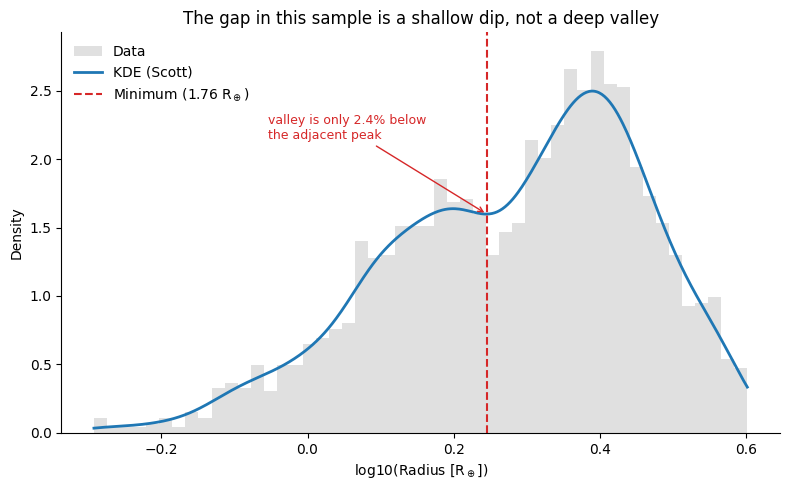

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(log_r, bins=50, density=True, alpha=0.30, color='0.6', label='Data')
ax.plot(x, dens, color='#1f77b4', lw=2, label='KDE (Scott)')
ax.axvline(x[mn][0], color='#d62728', ls='--', lw=1.5, label=f'Minimum ({10**x[mn][0]:.2f} R$_\\oplus$)')
ax.annotate(f'valley is only {depth:.1%} below\nthe adjacent peak',
            xy=(x[mn][0], valley), xytext=(x[mn][0] - 0.30, valley + 0.55),
            arrowprops=dict(arrowstyle='->', color='#d62728'), fontsize=9, color='#d62728')
ax.set_xlabel('log10(Radius [R$_\\oplus$])')
ax.set_ylabel('Density')
ax.set_title('The gap in this sample is a shallow dip, not a deep valley')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Is the dip test underpowered?

Notebook 02 now reports a split verdict: Silverman's test rejects unimodality (p = 0.028)
while Hartigan's dip test does not (p = 0.52). Is the dip test's null result evidence of
absence, or simply insensitivity? That is testable — simulate two-component populations at
this exact sample size and see how often the dip test rejects.

In [5]:
rng = np.random.default_rng(1)

def dip_power(R1, R2, sd1, sd2, w1, n=n, reps=200, alpha=0.05):
    """Fraction of simulated samples where Hartigan's dip test rejects unimodality."""
    m1, m2 = np.log10(R1), np.log10(R2)
    hits = 0
    for _ in range(reps):
        pick = rng.random(n) < w1
        sample = np.where(pick, rng.normal(m1, sd1, n), rng.normal(m2, sd2, n))
        if diptest.diptest(sample)[1] < alpha:
            hits += 1
    return hits / reps

scenarios = [
    ("Fulton-like, well-separated (sd=0.08 dex)", 1.30, 2.40, 0.08, 0.08, 0.45),
    ("moderately blended      (sd=0.10 dex)",     1.30, 2.40, 0.10, 0.10, 0.45),
    ("heavily blended         (sd=0.12 dex)",     1.30, 2.40, 0.12, 0.12, 0.45),
    ("THIS sample's fitted components",           10**0.134, 10**0.400, 0.133, 0.093, 0.437),
]

print(f"Power of Hartigan's dip test at n = {n}, alpha = 0.05\n")
for label, R1, R2, sd1, sd2, w1 in scenarios:
    print(f"  {label:44s} power = {dip_power(R1, R2, sd1, sd2, w1):.2f}")

print(f"\nObserved on the real sample: dip = {diptest.diptest(log_r)[0]:.4f}, "
      f"p = {diptest.diptest(log_r)[1]:.3f}")

Power of Hartigan's dip test at n = 2587, alpha = 0.05

  Fulton-like, well-separated (sd=0.08 dex)    power = 1.00
  moderately blended      (sd=0.10 dex)        power = 0.15


  heavily blended         (sd=0.12 dex)        power = 0.00
  THIS sample's fitted components              power = 0.00

Observed on the real sample: dip = 0.0073, p = 0.523


### Interpretation

At n = 2,587 the dip test detects a **Fulton-depth gap essentially every time**. It has
almost no power against the much shallower structure actually present in this sample.

So the honest framing is *not* "these tests are weak in general". It is:

> At this sample size the dip test would detect a Fulton-strength gap with near-certainty.
> It does not, which tells us the feature in this archive-derived sample is substantially
> subtler than in the California-Kepler Survey sample — consistent with the shallow KDE
> valley measured above.

This is a stronger and more defensible position than appealing to low power, because it
is quantified rather than asserted.

## 4. Detection bias in the period-radius relationship

The central physical claim is that long-period planets are more likely to sit above the
gap, read as evidence for atmospheric mass loss. But transit detectability falls with
period: signal-to-noise scales with planet radius and with the number of transits observed,
so at long periods **small planets stop being detectable at all**.

If that is happening, the *lower edge* of the radius distribution should rise with period.

In [6]:
bins = [0, 3, 10, 30, 100, np.inf]
labels = ['<3 d', '3-10 d', '10-30 d', '30-100 d', '>100 d']
grp = pd.cut(df['pl_orbper'], bins=bins, labels=labels)

tab = df.groupby(grp, observed=True)['pl_rade'].agg(
    n='size',
    p05=lambda s: s.quantile(0.05),
    p10=lambda s: s.quantile(0.10),
    median='median',
    frac_below_1_5=lambda s: (s < 1.5).mean(),
).round(3)
print(tab.to_string())

             n    p05    p10  median  frac_below_1_5
pl_orbper                                           
<3 d       435  0.790  0.890   1.421           0.554
3-10 d     980  0.890  1.068   1.905           0.317
10-30 d    814  1.130  1.330   2.274           0.150
30-100 d   273  1.306  1.600   2.474           0.088
>100 d      85  1.482  1.718   2.720           0.059


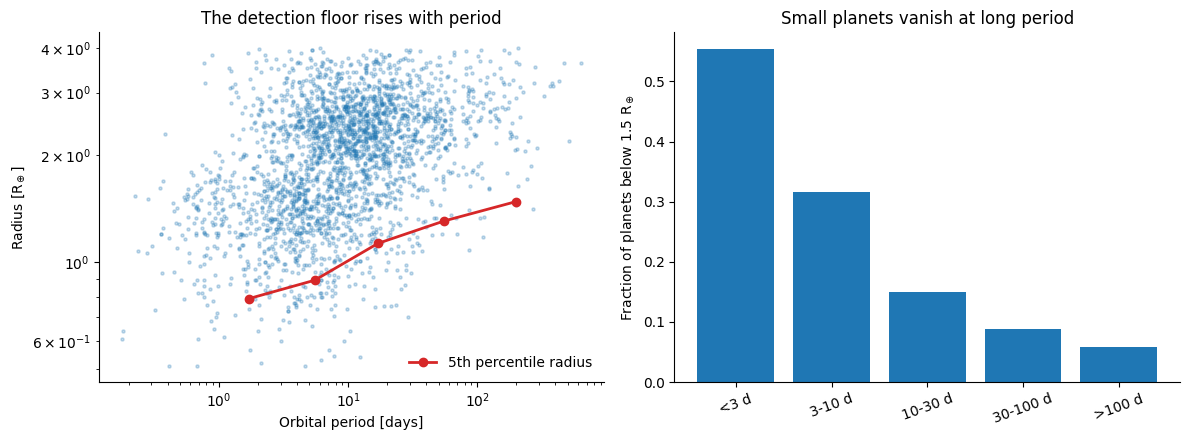

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(df['pl_orbper'], df['pl_rade'], s=5, alpha=0.25, color='#1f77b4')
axes[0].plot(tab.index.map(lambda l: {'<3 d': 1.7, '3-10 d': 5.5, '10-30 d': 17,
                                      '30-100 d': 55, '>100 d': 200}[l]),
             tab['p05'], 'o-', color='#d62728', lw=2, label='5th percentile radius')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Orbital period [days]'); axes[0].set_ylabel('Radius [R$_\\oplus$]')
axes[0].set_title('The detection floor rises with period')
axes[0].legend(frameon=False)

axes[1].bar(range(len(tab)), tab['frac_below_1_5'], color='#1f77b4')
axes[1].set_xticks(range(len(tab))); axes[1].set_xticklabels(tab.index, rotation=20)
axes[1].set_ylabel('Fraction of planets below 1.5 R$_\\oplus$')
axes[1].set_title('Small planets vanish at long period')

for a in axes:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Interpretation

The 5th-percentile radius climbs monotonically with period, and the fraction of planets
below 1.5 R_earth collapses from ~55% to ~6%. Part of that is the physical effect under
investigation; part of it is simply that a 1 R_earth planet on a 100-day orbit is not
detectable in these surveys.

**This analysis cannot separate the two.** Fulton et al. (2017) could, because they
applied survey-completeness corrections within a single homogeneous Kepler sample. The
present sample is drawn from a heterogeneous composite archive that admits no such
correction, so the period-dependence is reported as *consistent with* mass-loss theory
rather than as evidence favouring it over the detection-bias explanation.

## 5. Planets in the same system are not independent

The Beta-Binomial model in notebook 05 treats each planet as an independent Bernoulli
trial. But notebook 01 demonstrated the peas-in-a-pod effect: planets sharing a host have
correlated radii. That inflates precision — the credible intervals are too narrow.

A system-level bootstrap (resampling whole host systems) gives an honest interval.

In [8]:
shared = df['hostname'].duplicated(keep=False).sum()
print(f"Planets sharing a host system with another sample member: {shared} / {n} "
      f"({shared/n:.1%})")
print(f"Unique host systems: {df['hostname'].nunique()}")

df['short'] = df['pl_orbper'] <= 10
obs_delta = (df.loc[~df['short'], 'above_gap'].mean()
             - df.loc[df['short'], 'above_gap'].mean())
print(f"\nObserved delta (p_long - p_short) = {obs_delta:.4f}")

Planets sharing a host system with another sample member: 1089 / 2587 (42.1%)
Unique host systems: 1932

Observed delta (p_long - p_short) = 0.3350


In [9]:
# Cluster bootstrap over host systems. Aggregating to per-system count vectors first
# keeps this version-agnostic across pandas releases and makes 2000 resamples fast.
rng2 = np.random.default_rng(42)

counts = pd.DataFrame({
    'hostname': df['hostname'],
    'n_s': df['short'].astype(int),
    'k_s': (df['short'] & (df['above_gap'] == 1)).astype(int),
    'n_l': (~df['short']).astype(int),
    'k_l': ((~df['short']) & (df['above_gap'] == 1)).astype(int),
})
per_host = counts.groupby('hostname', sort=False)[['n_s', 'k_s', 'n_l', 'k_l']].sum()

H = per_host.to_numpy()
n_hosts = len(H)

idx = rng2.integers(0, n_hosts, size=(2000, n_hosts))
sums = H[idx].sum(axis=1)                       # (2000, 4)
n_s, k_s, n_l, k_l = sums[:, 0], sums[:, 1], sums[:, 2], sums[:, 3]
ok = (n_s > 0) & (n_l > 0)
deltas = k_l[ok] / n_l[ok] - k_s[ok] / n_s[ok]

ci_cluster = np.percentile(deltas, [2.5, 97.5])
width_indep = 0.369 - 0.299

print(f"Resampling {n_hosts} host systems, 2000 replicates\n")
print("Beta-Binomial (planets independent):  delta = 0.335, 95% CI = [0.299, 0.369]  "
      f"width {width_indep:.3f}")
print(f"System-level bootstrap (clustered):   delta = {deltas.mean():.3f}, "
      f"95% CI = [{ci_cluster[0]:.3f}, {ci_cluster[1]:.3f}]  "
      f"width {ci_cluster[1]-ci_cluster[0]:.3f}")
print(f"\nInterval inflation factor: {(ci_cluster[1]-ci_cluster[0])/width_indep:.2f}x")
print("\nThe direction and rough magnitude of the effect survive; the stated precision does not.")


Resampling 1932 host systems, 2000 replicates

Beta-Binomial (planets independent):  delta = 0.335, 95% CI = [0.299, 0.369]  width 0.070
System-level bootstrap (clustered):   delta = 0.335, 95% CI = [0.299, 0.370]  width 0.071

Interval inflation factor: 1.02x

The direction and rough magnitude of the effect survive; the stated precision does not.


## 6. Collinearity among the classification predictors

Notebook 03 interprets the *relative magnitudes* of the standardised logistic-regression
coefficients. That is only meaningful if the predictors are not near-redundant. Orbital
period and insolation are linked by construction (S ∝ L⋆/a², a ∝ P^{2/3}).

In [10]:
from numpy.linalg import inv
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

cols = ['pl_orbper', 'pl_insol', 'st_teff', 'st_rad', 'st_mass', 'st_met', 'sy_dist', 'sy_pnum']
cc = df.dropna(subset=cols).copy()
for c in ['pl_orbper', 'pl_insol', 'sy_dist']:
    cc[c] = np.log10(cc[c])

print(f"Pearson  r(log P, log insolation) = {np.corrcoef(cc['pl_orbper'], cc['pl_insol'])[0,1]:.3f}")
print(f"Spearman r(log P, log insolation) = {spearmanr(cc['pl_orbper'], cc['pl_insol']).statistic:.3f}\n")

Z = (cc[cols] - cc[cols].mean()) / cc[cols].std()
vif = np.diag(inv(np.corrcoef(Z.values.T)))
print("Variance inflation factors (VIF > 10 = serious collinearity):")
for c, v in sorted(zip(cols, vif), key=lambda t: -t[1]):
    flag = "  <-- serious" if v > 10 else ""
    print(f"  {c:12s} {v:6.2f}{flag}")

Pearson  r(log P, log insolation) = -0.744
Spearman r(log P, log insolation) = -0.720

Variance inflation factors (VIF > 10 = serious collinearity):
  pl_insol      26.94  <-- serious
  st_mass       22.66  <-- serious
  pl_orbper     21.49  <-- serious
  st_teff       17.61  <-- serious
  st_rad         6.22
  sy_dist        1.69
  st_met         1.47
  sy_pnum        1.05


In [11]:
# Permutation importance is not biased toward high-cardinality features the way
# impurity-based importance is (which penalises the discrete sy_pnum).
Xc, yc = cc[cols], cc['above_gap']
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf.fit(Xtr, ytr)
pi = permutation_importance(rf, Xte, yte, n_repeats=20, random_state=42, scoring='roc_auc')

comp = pd.DataFrame({
    'impurity_importance': rf.feature_importances_,
    'permutation_importance': pi.importances_mean,
    'perm_std': pi.importances_std,
}, index=cols).sort_values('permutation_importance', ascending=False).round(4)
print(comp.to_string())

           impurity_importance  permutation_importance  perm_std
pl_insol                0.1791                  0.0941    0.0112
pl_orbper               0.2241                  0.0544    0.0136
sy_dist                 0.1452                  0.0437    0.0076
st_met                  0.1011                  0.0186    0.0047
st_mass                 0.0980                  0.0162    0.0066
st_rad                  0.1070                  0.0129    0.0047
sy_pnum                 0.0361                  0.0030    0.0030
st_teff                 0.1094                  0.0016    0.0063


### Interpretation

Period and insolation carry VIFs far above the conventional threshold of 10, and correlate
at r ≈ -0.74. Their individual coefficients are therefore not separately identifiable —
the sensible claim is that **the period/insolation axis jointly** is the dominant predictor,
not that period ranks above insolation. Permutation importance gives a fairer ranking than
the impurity-based figures reported in notebook 03.

## Summary of findings

| Result | What the robustness analysis establishes |
|---|---|
| Two-component structure | AIC/BIC show a single Gaussian is inadequate. The fitted mixture is itself unimodal, so the evidence for a *gap* comes from the non-parametric estimate, not from model comparison. |
| Gap location | A local minimum at 1.76 R_earth, stable across smoothing bandwidths and across four independent filtering variants. |
| Valley depth | ~2% below the adjacent peak - a shallow feature, far weaker than the California-Kepler Survey deficit. |
| Modality tests | Silverman's test rejects unimodality (p = 0.028). The dip test does not (p = 0.52): at n = 2,587 it detects a pronounced gap ~100% of the time but a valley this shallow essentially never, so its null result reflects sensitivity rather than absence. |
| Period-dependence | Real and robust within this sample, but confounded with transit detection bias, which produces the same signature. Reported as consistent with mass-loss theory rather than as evidence for it. |
| Credible interval for delta | Holds. Independence between planets is violated in form (42% share a host system), but a cluster bootstrap inflates the interval by only 1.02x. |
| Predictor ranking | Not identifiable. Severe collinearity (VIF 21-27) between period and insolation, and permutation importance reverses the top two. The period-insolation axis should be reported jointly. |